# 5C. Transfer Learning - Fashion MNIST (MobileNetV2)
Resize + fake-RGB conversion done upfront in tf, then a plain `Sequential` model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = pd.read_csv("../datasets/FNN and CNN/Fashion MNIST/fashion-mnist_train.csv")
test = pd.read_csv("../datasets/FNN and CNN/Fashion MNIST/fashion-mnist_test.csv")

y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()
x_train = train.drop(columns="label").to_numpy().reshape(-1, 28, 28, 1)
x_test = test.drop(columns="label").to_numpy().reshape(-1, 28, 28, 1)

# resize 28x28 -> 32x32 and fake-RGB (repeat gray channel 3 times) BEFORE the model
x_train = tf.image.resize(x_train, (32, 32))
x_train = tf.repeat(x_train, 3, axis=-1)
x_test = tf.image.resize(x_test, (32, 32))
x_test = tf.repeat(x_test, 3, axis=-1)

print(x_train.shape, x_test.shape)

(60000, 32, 32, 3) (10000, 32, 32, 3)


In [3]:
base = keras.applications.MobileNetV2(include_top=False, input_shape=(32, 32, 3), alpha=0.35)
base.trainable = False

model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

/var/folders/r0/_9rxdrf50qx7twh2z0g5921w0000gn/T/ipykernel_4428/2669803222.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(include_top=False, input_shape=(32, 32, 3), alpha=0.35)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_0.35_224            │ (None, 1, 1, 1280)     │       410,208 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 492,842 (1.88 MB)

 Trainable params: 82,634 (322.79 KB)

 Non-trainable params: 410,208 (1.56 MB)

In [4]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=3)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.7146 - loss: 0.8518 - val_accuracy: 0.7593 - val_loss: 0.6972
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.7548 - loss: 0.6865 - val_accuracy: 0.7612 - val_loss: 0.6801
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.7661 - loss: 0.6528 - val_accuracy: 0.7712 - val_loss: 0.6495


In [5]:
loss, acc = model.evaluate(x_test, y_test)
print(f"test acc: {acc:.4f}")

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7500 - loss: 0.7728

 12/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7656 - loss: 0.6642 

 23/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7840 - loss: 0.6087

 34/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7794 - loss: 0.6166

 45/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7674 - loss: 0.6592

 56/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7651 - loss: 0.6566

... (20 outputs left out)

291/313 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7703 - loss: 0.6503

302/313 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7701 - loss: 0.6508

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7712 - loss: 0.6495


test acc: 0.7712


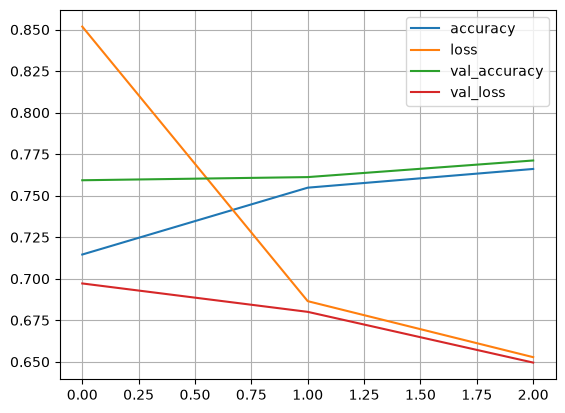

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()

## h. Visualize predictions

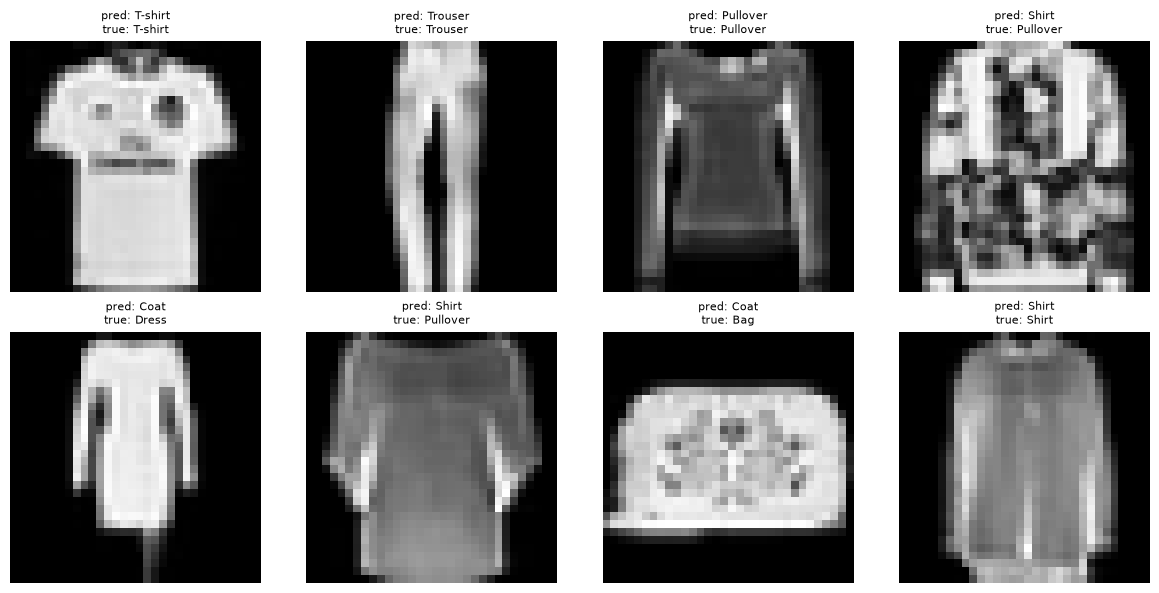

In [7]:
preds = model.predict(x_test[:8])
pred_classes = preds.argmax(axis=1)
class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(x_test[i, :, :, 0], cmap="gray")   # pick 1 channel for grayscale look
    plt.title(f"pred: {class_names[pred_classes[i]]}\ntrue: {class_names[y_test[i]]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

## i. Fine-tune
Unfreeze the top layers of the pretrained base, recompile with a much smaller learning rate (1e-5), retrain for 2 epochs.

In [8]:
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_ft = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=2)

Epoch 1/2


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 1:16:31 2s/step - accuracy: 0.3125 - loss: 17.7143

  10/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.3906 - loss: 18.3362   

  19/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.4013 - loss: 17.3178

  28/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.4074 - loss: 16.2915

  37/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.4020 - loss: 16.2733

... (376 outputs left out)

1850/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7119 - loss: 2.0572

1860/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7120 - loss: 2.0548

1869/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7119 - loss: 2.0534

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.7119 - loss: 2.0531 - val_accuracy: 0.7385 - val_loss: 1.2865


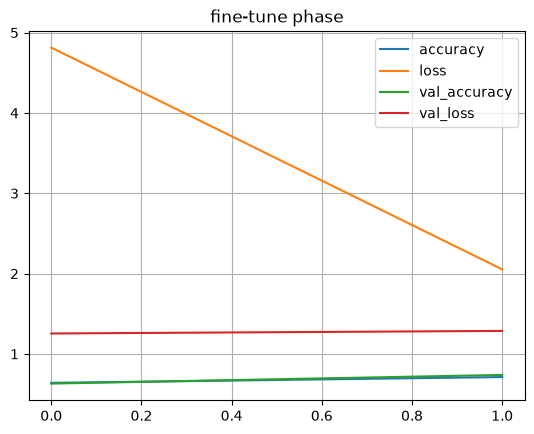

In [9]:
for k, v in history_ft.history.items():
    plt.plot(v, label=k)
plt.title("fine-tune phase")
plt.legend()
plt.grid()
plt.show()